In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

In [3]:
train = pd.read_csv("FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test = pd.read_csv("FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

x_train = train.iloc[:, 1:].values / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [4]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7093 - loss: 0.9334 - val_accuracy: 0.7800 - val_loss: 0.6741
Epoch 2/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 959us/step - accuracy: 0.7995 - loss: 0.6142 - val_accuracy: 0.8117 - val_loss: 0.5773
Epoch 3/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 927us/step - accuracy: 0.8170 - loss: 0.5473 - val_accuracy: 0.8193 - val_loss: 0.5398
Epoch 4/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 899us/step - accuracy: 0.8271 - loss: 0.5120 - val_accuracy: 0.8279 - val_loss: 0.5104
Epoch 5/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 861us/step - accuracy: 0.8313 - loss: 0.4903 - val_accuracy: 0.8346 - val_loss: 0.4909
Epoch 6/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8365 - loss: 0.4733 - val_accuracy: 0.8358 - val_loss: 0.4816
Epoch 7/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8399 - loss: 0.4617 - val_accuracy: 0.8425 - val_loss: 0.4678
Epoch 8/11
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8452 - loss: 0.4500 - val_accu

In [7]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 436us/step - accuracy: 0.8529 - loss: 0.4332
Test Loss: 0.4332338869571686
Test Accuracy: 0.8529000282287598


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


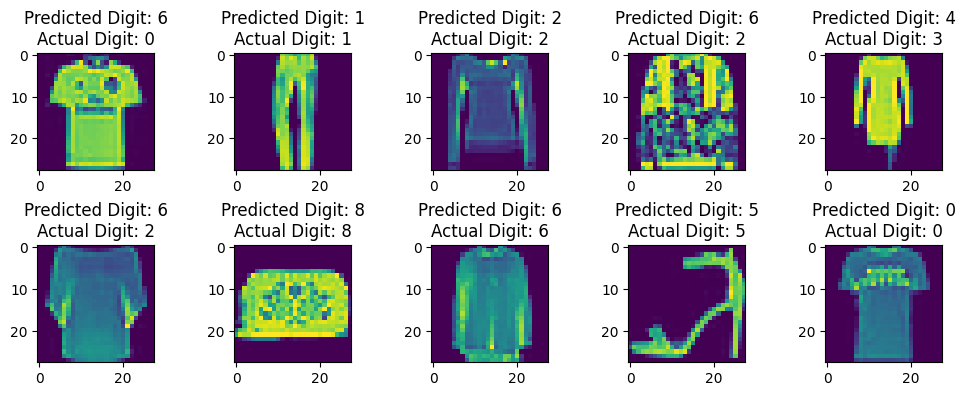

In [8]:
predictions = model.predict(x_test[:10])
predicted = predictions.argmax(axis = 1)

plt.figure(figsize=(10,4))
for i in range (10):
    plt.subplot(2 , 5 , i+1)
    plt.imshow(x_test[i].reshape(28 , 28))
    plt.title(f"Predicted Digit: {predicted[i]}\nActual Digit: {y_test[i]}")

plt.tight_layout()
plt.show()

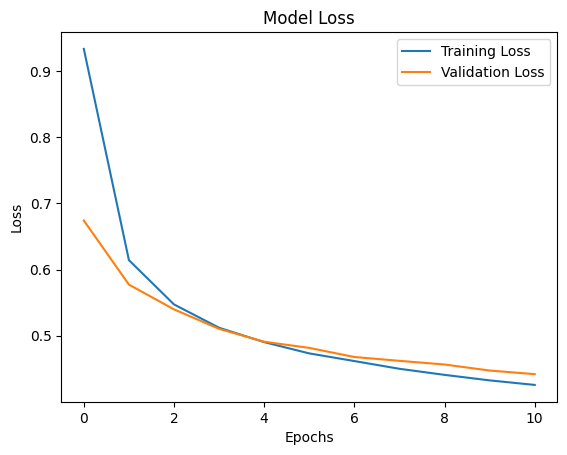

In [9]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

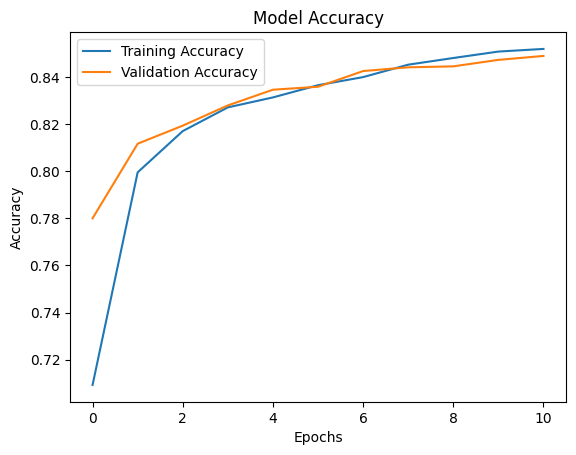

In [10]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [18]:
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

prediction = model.predict(x_test[:1])

print("Predicted:", class_names[np.argmax(prediction[0])])
print("Actual:", class_names[y_test[0]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted: T-shirt
Actual: T-shirt
